### Utils

In [1]:
import torch

In [35]:
def build_dataset(df):
    grouped = df.groupby("ecg_id")

    X = []
    y = []

    for _, group in grouped:
        signal = group[[f'channel-{i}' for i in range(12)]].values
        label = group[['NORM','MI','STTC','HYP','CD']].iloc[0].values

        X.append(signal)
        y.append(label)

    return np.array(X), np.array(y)

In [3]:
MAX_LEN = 1000 

def pad_signal(x):
    if len(x) > MAX_LEN:
        return x[:MAX_LEN]
    else:
        pad = np.zeros((MAX_LEN - len(x), x.shape[1]))
        return np.vstack([x, pad])

In [4]:
class ECGDataset(torch.utils.data.Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [5]:
def loop_fn(mode, dataset, dataloader, model, criterion, optimizer, device):
    if mode == "train":
        model.train()
    elif mode == "test":
        model.eval()

    cost = 0
    pbar = tqdm(dataloader, total=len(dataloader), desc=mode.title())
    
    for feature, target in pbar:
        feature, target = feature.to(device), target.to(device)
        output = model(feature)
        loss = criterion(output, target)

        if mode == "train":
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        cost += loss.item() * feature.shape[0]
    cost = cost / len(dataset)
    return cost

In [6]:
import numpy as np
from sklearn.metrics import f1_score, roc_auc_score

def evaluate_model(model, dataloader, device, threshold=0.5):
    model.eval()
    
    all_probs = []
    all_targets = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch = X_batch.to(device)

            probs = model(X_batch)  # output sigmoid (0-1)

            all_probs.append(probs.cpu().numpy())
            all_targets.append(y_batch.numpy())

    # gabungkan semua batch
    probs = np.vstack(all_probs)
    targets = np.vstack(all_targets)

    # thresholding → jadi prediksi 0/1
    y_pred = (probs > threshold).astype(int)

    # =====================
    # F1 Score
    # =====================
    f1_micro = f1_score(targets, y_pred, average='micro')
    f1_macro = f1_score(targets, y_pred, average='macro')

    # =====================
    # AUROC
    # =====================
    try:
        auc_macro = roc_auc_score(targets, probs, average='macro')
    except:
        auc_macro = None  # kalau ada label yang tidak muncul

    return {
        "f1_micro": f1_micro,
        "f1_macro": f1_macro,
        "auc_macro": auc_macro
    }

## Train

In [7]:
import sys
import os
sys.path.append(os.path.abspath('../code'))

from models.xresnet1d import xresnet1d101
from models.resnet1d import resnet1d_wang, wrn1d_22
from models.inception1d import inception1d
from models.rnn1d import RNN1d

C:\Users\asus_\miniconda3\envs\dlenv\Lib\site-packages\fastai\imports\core.py:29: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [8]:
from torch.utils.data import DataLoader
import pandas as pd
import numpy as np
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [36]:
train = pd.read_csv("gabungannya_train_lr.csv")
valid = pd.read_csv("gabungannya_valid_lr.csv")

In [22]:
train.head()

,ecg_id,channel-0,channel-1,channel-2,channel-3,channel-4,channel-5,channel-6,channel-7,channel-8,channel-9,channel-10,channel-11,NORM,MI,STTC,HYP,CD
0,1,-0.119,-0.055,0.064,0.086,-0.091,0.004,-0.069,-0.031,0.000,-0.026,-0.039,-0.079,1,0,0,0,0
1,1,-0.116,-0.051,0.065,0.083,-0.090,0.006,-0.064,-0.036,-0.003,-0.031,-0.034,-0.074,1,0,0,0,0
2,1,-0.120,-0.044,0.076,0.082,-0.098,0.016,-0.058,-0.034,-0.010,-0.028,-0.029,-0.069,1,0,0,0,0
3,1,-0.117,-0.038,0.080,0.077,-0.098,0.021,-0.050,-0.030,-0.015,-0.023,-0.022,-0.064,1,0,0,0,0
4,1,-0.103,-0.031,0.072,0.066,-0.087,0.021,-0.045,-0.027,-0.020,-0.019,-0.018,-0.058,1,0,0,0,0


In [12]:
train.columns

Index(['ecg_id', 'channel-0', 'channel-1', 'channel-2', 'channel-3',
       'channel-4', 'channel-5', 'channel-6', 'channel-7', 'channel-8',
       'channel-9', 'channel-10', 'channel-11', 'NORM', 'MI', 'STTC', 'HYP',
       'CD'],
      dtype='object')

In [23]:
train = train[['ecg_id', 'channel-7', 'channel-8', 'channel-9', 'NORM', 'MI', 'STTC', 'HYP', 'CD']]
valid = valid[['ecg_id', 'channel-7', 'channel-8', 'channel-9', 'NORM', 'MI', 'STTC', 'HYP', 'CD']]

In [24]:
print(train.head())
print(valid.head())

   ecg_id  channel-7  channel-8  channel-9  NORM  MI  STTC  HYP  CD
0       1     -0.031      0.000     -0.026     1   0     0    0   0
1       1     -0.036     -0.003     -0.031     1   0     0    0   0
2       1     -0.034     -0.010     -0.028     1   0     0    0   0
3       1     -0.030     -0.015     -0.023     1   0     0    0   0
4       1     -0.027     -0.020     -0.019     1   0     0    0   0
   ecg_id  channel-7  channel-8  channel-9  NORM  MI  STTC  HYP  CD
0       9     -0.818     -0.647     -0.452     1   0     0    0   0
1       9     -0.523     -0.454     -0.339     1   0     0    0   0
2       9     -0.147     -0.196     -0.188     1   0     0    0   0
3       9     -0.052     -0.136     -0.146     1   0     0    0   0
4       9     -0.001     -0.098     -0.097     1   0     0    0   0


In [37]:
X_train, y_train = build_dataset(train)
X_val, y_val = build_dataset(valid)

In [38]:
X_train.shape, X_val.shape, y_train.shape, y_val.shape

((17418, 1000, 12), (2198, 1000, 12), (17418, 5), (2198, 5))

In [39]:
X_train = np.transpose(X_train, (0, 2, 1))
X_val   = np.transpose(X_val, (0, 2, 1))

In [40]:
train_dataset = ECGDataset(X_train, y_train)
val_dataset   = ECGDataset(X_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=32)
val_loader   = DataLoader(val_dataset, batch_size=32)

In [41]:
X_val.shape

(2198, 12, 1000)

In [30]:
from torch import optim, nn
from tqdm.auto import tqdm
from jcopdl.callback import Callback

# Training Preparation

### Inception

In [42]:
inception = inception1d(input_channels=12, num_classes=5).to(device)

In [43]:
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(inception.parameters(), lr=1e-3)
callback = Callback(inception, outdir="Inception/coba lgi 12", early_stop_patience=10)

Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch     1
Train_cost  = 0.4122 | Test_cost  = 0.3296 | 


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch     2
Train_cost  = 0.3218 | Test_cost  = 0.3134 | 


... (38 outputs left out)


Epoch    15
Train_cost  = 0.2263 | Test_cost  = 0.3082 | 
==> EarlyStop patience =  9 | Best test_cost: 0.2885


Train:   0%|          | 0/545 [00:00<?, ?it/s]

Test:   0%|          | 0/69 [00:00<?, ?it/s]


Epoch    16
Train_cost  = 0.2199 | Test_cost  = 0.3024 | 
==> EarlyStop patience = 10 | Best test_cost: 0.2885
==> Execute Early Stopping at epoch: 16 | Best test_cost: 0.2885
==> Best model is saved at Inception/coba lgi 12


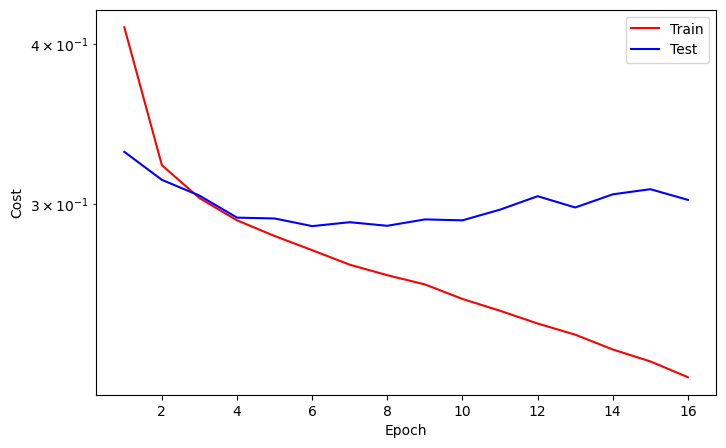

In [44]:
while True:
    train_cost = loop_fn("train", train_dataset, train_loader, inception, criterion, optimizer, device)
    with torch.no_grad():
        test_cost = loop_fn("test", val_dataset, val_loader, inception, criterion, optimizer, device)
        
    callback.log(train_cost, test_cost)
    callback.save_checkpoint()
    callback.cost_runtime_plotting()
    if callback.early_stopping(inception, monitor='test_cost'):
        callback.plot_cost()
        break

In [45]:
# 12 lead
metrics = evaluate_model(inception, val_loader, device)

print(metrics)

{'f1_micro': 0.7288781858318282, 'f1_macro': 0.6881367755363235, 'auc_macro': 0.9148203799073403}


In [34]:
# # 3 lead
# metrics = evaluate_model(inception, val_loader, device)

# print(metrics)

{'f1_micro': 0.6417380405264257, 'f1_macro': 0.5656347132473146, 'auc_macro': 0.856514615782368}


In [52]:
# # 5 lead
# metrics = evaluate_model(inception, val_loader, device)

# print(metrics)

{'f1_micro': 0.718923198733175, 'f1_macro': 0.6608145233538065, 'auc_macro': 0.9002082387057181}


## Predict

In [26]:
test = pd.read_csv("gabungannya_test_lr.csv")
test.head()

,ecg_id,channel-0,channel-1,channel-2,channel-3,channel-4,channel-5,channel-6,channel-7,channel-8,channel-9,channel-10,channel-11,NORM,MI,STTC,HYP,CD
0,9,-0.145,-0.097,0.049,0.121,-0.096,-0.024,-0.579,-0.818,-0.647,-0.452,-0.269,-0.032,1,0,0,0,0
1,9,-0.115,-0.083,0.032,0.099,-0.073,-0.025,-0.369,-0.523,-0.454,-0.339,-0.246,-0.041,1,0,0,0,0
2,9,-0.064,-0.060,0.005,0.062,-0.034,-0.027,-0.088,-0.147,-0.196,-0.188,-0.199,-0.040,1,0,0,0,0
3,9,-0.093,-0.101,-0.008,0.097,-0.042,-0.054,-0.006,-0.052,-0.136,-0.146,-0.164,-0.037,1,0,0,0,0
4,9,-0.081,-0.108,-0.027,0.095,-0.027,-0.067,0.028,-0.001,-0.098,-0.097,-0.148,-0.034,1,0,0,0,0


In [27]:
X_fix, y_fix = build_dataset(test)

In [28]:
X_fix = np.transpose(X_fix, (0, 2, 1))

In [29]:
test_dataset = ECGDataset(X_fix, y_fix)
test_loader = DataLoader(test_dataset, batch_size=32)

In [30]:
feature, target = next(iter(test_loader))
feature, target = feature.to(device), target.to(device)

In [31]:
inception.eval()
with torch.no_grad():
    output = inception(feature)
    probs = torch.sigmoid(output)
    preds = (probs > 0.5).float()
preds

tensor([[1., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0.],
        [0., 0., 0., 0., 1.],
        [1., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0.],
        [1., 0., 0., 0., 1.],
        [1., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0.],
        [1., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0.],
        [0., 1., 1., 0., 0.],
        [1., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0.],
        [0., 0., 1., 1., 1.],
        [1., 0., 0., 0., 0.],
        [0., 1., 0., 0., 1.],
        [1., 0., 0., 0., 0.],
        [0., 0., 0., 0., 1.],
        [1., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0.]], device='cuda:0')

In [32]:
for i in range(len(preds)):
    is_correct = torch.equal(preds[i], target[i])

    if is_correct:
        print(f"[OK] Sample {i}")
    else:
        print(f"[ERROR] Sample {i}")
    print("Pred: ", preds[i])
    print("GT : ", target[i])
    print()

[OK] Sample 0
Pred:  tensor([1., 0., 0., 0., 0.], device='cuda:0')
GT :  tensor([1., 0., 0., 0., 0.], device='cuda:0')

[OK] Sample 1
Pred:  tensor([1., 0., 0., 0., 0.], device='cuda:0')
GT :  tensor([1., 0., 0., 0., 0.], device='cuda:0')

[OK] Sample 2
Pred:  tensor([1., 0., 0., 0., 0.], device='cuda:0')
GT :  tensor([1., 0., 0., 0., 0.], device='cuda:0')

[OK] Sample 3
Pred:  tensor([1., 0., 0., 0., 0.], device='cuda:0')
GT :  tensor([1., 0., 0., 0., 0.], device='cuda:0')

[OK] Sample 4
Pred:  tensor([1., 0., 0., 0., 0.], device='cuda:0')
GT :  tensor([1., 0., 0., 0., 0.], device='cuda:0')

[OK] Sample 5
Pred:  tensor([0., 1., 0., 0., 0.], device='cuda:0')
GT :  tensor([0., 1., 0., 0., 0.], device='cuda:0')

[OK] Sample 6
Pred:  tensor([0., 0., 0., 0., 1.], device='cuda:0')
GT :  tensor([0., 0., 0., 0., 1.], device='cuda:0')

[OK] Sample 7
Pred:  tensor([1., 0., 0., 0., 0.], device='cuda:0')
GT :  tensor([1., 0., 0., 0., 0.], device='cuda:0')

[OK] Sample 8
Pred:  tensor([1., 0., 0.,

In [34]:
metrics = evaluate_model(inception, test_loader, device)
print(metrics)

{'f1_micro': 0.7496050552922591, 'f1_macro': 0.7012975788605568, 'auc_macro': 0.9257740280577351}


In [35]:
inception

Inception1d(
  (layers): Sequential(
    (0): InceptionBackbone(
      (im): ModuleList(
        (0): InceptionBlock1d(
          (bottleneck): Conv1d(12, 32, kernel_size=(1,), stride=(1,), bias=False)
          (convs): ModuleList(
            (0): Conv1d(32, 32, kernel_size=(39,), stride=(1,), padding=(19,), bias=False)
            (1): Conv1d(32, 32, kernel_size=(19,), stride=(1,), padding=(9,), bias=False)
            (2): Conv1d(32, 32, kernel_size=(9,), stride=(1,), padding=(4,), bias=False)
          )
          (conv_bottle): Sequential(
            (0): MaxPool1d(kernel_size=3, stride=1, padding=1, dilation=1, ceil_mode=False)
            (1): Conv1d(12, 32, kernel_size=(1,), stride=(1,), bias=False)
          )
          (bn_relu): Sequential(
            (0): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (1): ReLU()
          )
        )
        (1-5): 5 x InceptionBlock1d(
          (bottleneck): Conv1d(128, 32, kernel_size=(1,